# 00 · Bitcoin-specific mean reversion

Can a time-varying Nasdaq hedge isolate a predictable Bitcoin-specific return?

Run this notebook from top to bottom. It is independent of the execution state of other notebooks.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from btc_nasdaq.config import project_root, load_config
from btc_nasdaq.research import research_context, run_period
from btc_nasdaq.plotting import set_theme, save_figure, shade_holdout, PALETTE
from btc_nasdaq.data import sha256

set_theme()
pd.options.display.float_format = "{:,.4f}".format
ROOT = project_root()
c = research_context(ROOT)
cfg, prices, returns = c["cfg"], c["prices"], c["returns"]
betas, beta, signal = c["betas"], c["beta"], c["signal"]
HOLDOUT = cfg["validation"]["holdout_start"]
summary_path = ROOT / "reports/tables/summary.json"
if not summary_path.exists():
    raise RuntimeError("Run uv run python scripts/run_research.py before executing the notebooks.")
run_record = json.loads(summary_path.read_text())
if (run_record["config_sha256"] != sha256(ROOT / "configs/research.toml") or
    run_record["data_sha256"] != sha256(ROOT / "data/processed/aligned_prices.parquet")):
    raise RuntimeError("Summary tables are stale. Re-run scripts/run_research.py.")
display(Markdown(f"**Data:** {prices.index.min():%Y-%m-%d} to {prices.index.max():%Y-%m-%d} "
                 f"· **{len(prices):,} synchronized sessions** · BTC-USD / QQQ · "
                 f"**Fixed baseline:** {cfg['strategy']['model']}"))

**Data:** 2018-01-02 to 2026-11-06 · **2,225 synchronized sessions** · BTC-USD / QQQ · **Fixed baseline:** ewma_63

## The hypothesis has three separate tests

1. **Dependence:** the BTC–Nasdaq relationship changes across regimes.
2. **Hedging:** a causal estimate of that relationship reduces future Nasdaq exposure.
3. **Alpha:** a Bitcoin-specific shock predicts a profitable reversal after delays and costs.

Passing test 1 or 2 does not establish test 3. The intended exposure is BTC-specific reversal;
the unwanted exposure is the fitted linear QQQ return component. Jumps, liquidity, rates,
nonlinear market effects, venue risk and estimation error remain.

For aligned simple returns, the minimum-variance one-factor hedge is

$$\hat\beta_t=\frac{\widehat{\mathrm{Cov}}_t(r^{BTC},r^{QQQ})}{\widehat{\mathrm{Var}}_t(r^{QQQ})}
=\hat\rho_t\frac{\hat\sigma^{BTC}_t}{\hat\sigma^{QQQ}_t}.$$

A long BTC dollar exposure $D_B$ requires signed QQQ exposure $D_Q=-\hat\beta D_B$.
Correlation alone is not the hedge ratio, and beta neutrality is not dollar neutrality.

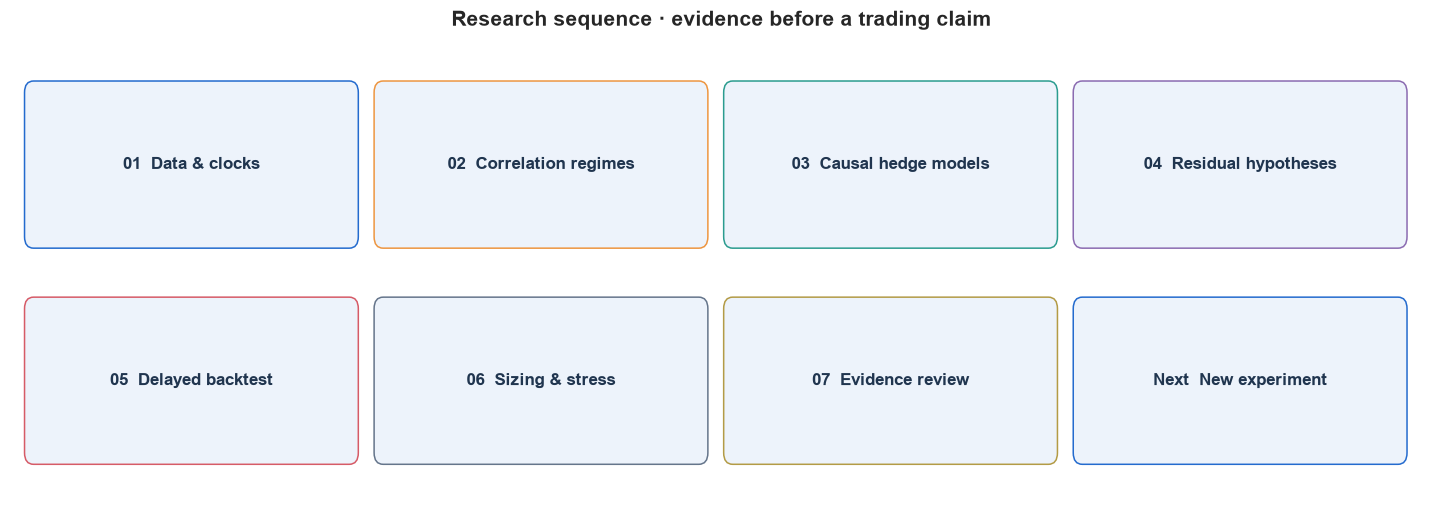

In [2]:
from matplotlib.patches import FancyBboxPatch
steps = ["01  Data & clocks", "02  Correlation regimes", "03  Causal hedge models", "04  Residual hypotheses",
         "05  Delayed backtest", "06  Sizing & stress", "07  Evidence review", "Next  New experiment"]
fig, ax = plt.subplots(figsize=(13, 4.5))
for i, label in enumerate(steps):
    x, y = (i % 4) * 3.1, 1.5 - (i // 4) * 1.5
    ax.add_patch(FancyBboxPatch((x, y), 2.8, 1., boxstyle="round,pad=.08", facecolor="#edf3fb", edgecolor=PALETTE[i % 7]))
    ax.text(x + 1.4, y + .5, label, ha="center", va="center", fontsize=11, weight="bold", color="#20354F")
ax.set(xlim=(-.2, 12.4), ylim=(-.3, 2.9), title="Research sequence · evidence before a trading claim")
ax.axis("off")
plt.show()

## What is fixed in this first pass?

- **Universe:** Coinbase BTC-USD spot versus QQQ adjusted returns; USD exposures.
- **Clock:** last completed BTC hourly candle at the actual Nasdaq session close. Friday–Monday
  returns include the whole weekend on both legs; the QQQ hedge cannot be resized while closed.
- **Model candidates:** expanding OLS, 63/126/252-session rolling OLS, EWMA with 63-session half-life,
  and a filtered random-walk Kalman regression. No full-sample smoothing.
- **Trading baseline:** EWMA beta; 20-session cumulative residual shock; entry at |z| ≥ 1.5;
  exit at reversion toward zero, |z| ≥ 3.5, or 10 decision sessions. This is a testable reversal
  hypothesis, not an assertion that a BTC–QQQ price spread is stationary.
- **Sample split:** training through 2021, validation 2022–2023, holdout 2024 onward. Model states
  update sequentially using past observations; signal rules are fixed. Each split starts flat.
- **Execution:** observe close t → submit for close t+1 → first P&L interval ends at t+2.
- **Costs:** 10 bp BTC / 2 bp QQQ per dollar traded; 5% annual short carry and debit financing,
  zero cash yield. Costs and margin mechanics remain illustrative.

In [3]:
display(pd.DataFrame({"value": {**cfg["strategy"], "train_end": cfg["validation"]["train_end"],
                               "validation_end": cfg["validation"]["validation_end"]}}))
manifest = json.loads((ROOT / "data/raw/manifest.json").read_text())
display(pd.Series({k: manifest[k] for k in ["actual_first_session", "actual_last_session", "sessions", "btc_hourly_rows", "alignment"]}, name="Provenance"))

,value
model,ewma_63
lookback,20
entry_z,1.5000
exit_z,0.2500
stop_z,3.5000
max_holding,10
target_vol,0.1000
max_gross,1.5000
execution_lag,2
btc_cost_bps,10.0000


actual_first_session                                           2018-01-02
actual_last_session                                            2026-11-06
sessions                                                             2225
btc_hourly_rows                                                     77527
alignment               Coinbase close of [Nasdaq close - 1h, Nasdaq c...
Name: Provenance, dtype: object

## How to use the lab

Change assumptions in `configs/research.toml`, put reusable logic in `src/btc_nasdaq`, and use these
notebooks for inspection and interpretation. Run `scripts/run_research.py` to refresh the summary
tables, then `scripts/execute_notebooks.py` to execute all notebooks and export HTML.

Raw data stays local. A new machine runs `scripts/fetch_data.py`; the repository includes executed
notebooks and selected summary figures so the original pass remains readable without a download.

**Research context:** [CME's 2025 study](https://www.cmegroup.com/insights/economic-research/2025/why-is-bitcoin-moving-in-tandem-with-equities.html)
documents stronger BTC–equity links after 2020. It motivates this test; it does not establish our
strategy's alpha. The layout follows [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/).
See `docs/methodology.md` and `docs/sources.md` for the full experiment contract.

---
**Research notes / feedback**

- Observation worth following up:
- Assumption to change in the next experiment:
- Evidence that would change the conclusion:

Record changes in `docs/research_log.md`. Once you inspect a holdout, it is no longer untouched data for a new variant.